# Energy distribution of spot F, tight cut (-82 V, DCRC1pB trigger)

*Sixth notebook of `relcal`. Draft prepared with Claude Code for A. Villano, 2026-11-01.*

The events close to the centre of the high-activity spot over the centre disc `F` (see `positions-82v-dcrc1pb.ipynb`): within `TIGHT_F` = 0.5 us of its centre in the plane of the 20 % delays, instead of the 1.5 us circle of `spots-82v-energy.ipynb`. Estimating the ordinary events of that place from the ring around the spot, about 95 % of the events inside the tight circle belong to the spot; a smaller circle is no purer. The selection and the energy are those of `spots-82v-energy.ipynb`: the energy is the **uncalibrated** sum of the six `integral`s (ADC counts x s). For comparison, the energy distribution of the events outside both spots. Everything comes from `spots_82v.py`.

Needs `goldpan` and the output of `r76-82v-dcrc1pb.dataset.toml` in `~/goldsluice-output/r76-82v-dcrc1pb`. Run with the `darkmatter_cli_env` kernel.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from spots_82v import SPOTS, TIGHT_F, in_spot, load, ring

d = load()
x0, y0, R = SPOTS["F"]
r = np.hypot(d["xdel"] - x0, d["ydel"] - y0)
tight = d["use"] & (r < TIGHT_F)
E = d["integral"].sum(axis=1)                      # the energy: the sum of the six integrals (ADC counts x s)

side = d["use"] & ring(d["xdel"], d["ydel"], "F")
background = side.sum() / (np.pi * ((2.2 * R) ** 2 - (1.5 * R) ** 2)) * np.pi * TIGHT_F ** 2
print(f"spot F, centre ({x0:+.2f}, {y0:+.2f}) us, radius {TIGHT_F} us: {tight.sum():,} events, "
      f"of which about {background:,.0f} ({background / tight.sum():.1%}) are ordinary events of that place (from the ring)")
p = np.percentile(E[tight], [10, 50, 90])
print("energy 10/50/90 %: " + "  ".join(f"{v:.2f}" for v in p))

# for comparison: the selected events away from both spots, farther than 1.5 x their radius (2.25 us) from either centre
outside = d["use"] & ~in_spot(d["xdel"], d["ydel"], "C", scale=1.5) & ~in_spot(d["xdel"], d["ydel"], "F", scale=1.5)
p = np.percentile(E[outside], [10, 50, 90])
print(f"outside the spots: {outside.sum():,} events, energy 10/50/90 %: " + "  ".join(f"{v:.2f}" for v in p))

spot F, centre (+1.60, +0.70) us, radius 0.5 us: 15,792 events, of which about 839 (5.3%) are ordinary events of that place (from the ring)
energy 10/50/90 %: 7.09  10.61  12.79
outside the spots: 313,494 events, energy 10/50/90 %: 5.43  7.52  11.47


## Spot F against the rest of the face

The tight spot F and the events outside both spots (farther than 2.25 us from either centre), each normalised to its number of events so the shapes can be compared; then the same on a log scale. The error bars are Poisson.

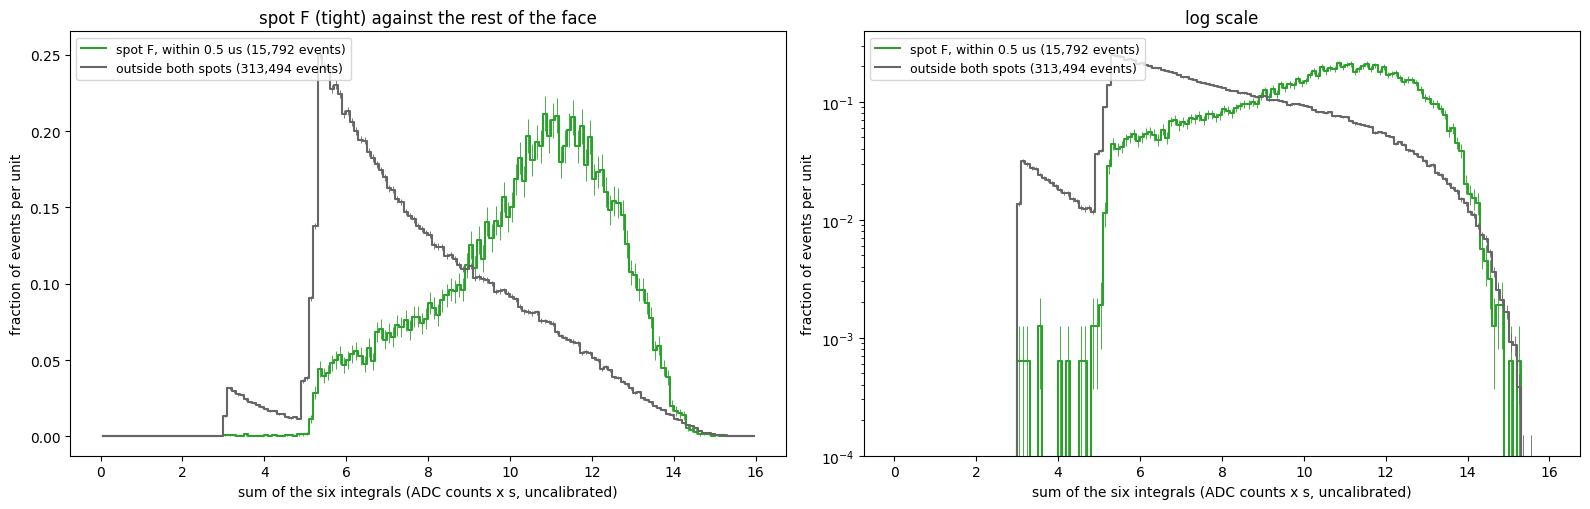

In [2]:
BINS = np.linspace(0, 16, 161)
centres = 0.5 * (BINS[1:] + BINS[:-1])
width = BINS[1] - BINS[0]
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
for ax, log in zip(axes, (False, True)):
    for m, c, label in ((tight, "C2", f"spot F, within {TIGHT_F} us ({tight.sum():,} events)"),
                        (outside, "0.4", f"outside both spots ({outside.sum():,} events)")):
        n, _ = np.histogram(E[m], BINS)
        f = 1 / (m.sum() * width)
        ax.step(centres, n * f, where="mid", color=c, linewidth=1.5, label=label)
        ax.errorbar(centres, n * f, yerr=np.sqrt(n) * f, fmt="none", ecolor=c, elinewidth=0.6)
    ax.set_xlabel("sum of the six integrals (ADC counts x s, uncalibrated)")
    ax.set_ylabel("fraction of events per unit")
    if log:
        ax.set_yscale("log")
        ax.set_ylim(1e-4, None)
    ax.set_title("log scale" if log else "spot F (tight) against the rest of the face")
    ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()
plt.show()

**Not done.** Any calibration of the energy (equal weights, ADC counts x s), and the subtraction of the ordinary events (about 5 % here, spread like the ring's distribution in `spots-82v-energy.ipynb`). The low edge near 5 is the trigger and the cut `total > 2` (series `07221113_1159` reaches lower, to about 3, see `spots-82v-energy.ipynb`); the upper edge near 14.5 is common to all events and not understood yet.